### Setting up the connection with the Database

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "Analysis":
    os.chdir("..")

In [2]:

import duckdb
con = duckdb.connect("ocean.duckdb", read_only=True)

In [3]:
con.sql("SHOW TABLES").df()

,name
0,bloom_events
1,bloom_frequency
2,chl_abs_exceed
3,chl_dineof
4,chl_erd
5,chl_model
6,chl_pixel_clim
7,cuti
8,cuti_average
9,event_rain


#### Loading in the data table that will be used for the modeling for Kelp

In [4]:
long_model =  con.execute("SELECT * FROM 'model_long'").df()
light_model =  con.execute("SELECT * FROM 'light_model'").df()

In [5]:
long_model

,quarter,kelp_biomass,avg_sst,avg_pdo,avg_cuti
0,2008-01-01,39.013001,13.097624,-1.183333,0.739013
1,2008-04-01,326.425187,14.153249,-1.546667,0.770022
2,2008-07-01,816.896073,18.691596,-1.313333,0.460989
3,2008-10-01,498.031191,16.084681,-1.020000,0.345978
4,2009-01-01,402.809243,13.482346,-1.576667,0.243500
...,...,...,...,...,...
68,2025-01-01,61.866007,13.362018,-0.993333,0.758933
69,2025-04-01,271.534719,15.265020,-1.843333,0.995242
70,2025-07-01,237.894648,18.882433,-2.693333,0.508391
71,2025-10-01,66.457176,17.591676,-1.076667,0.437870


In [6]:
light_model

,quarter,kelp_biomass,avg_sst,avg_pdo,avg_cuti,avg_kdpar
0,2012-01-01,148.322895,13.384606,-1.333333,0.392703,0.188747
1,2012-04-01,265.847722,14.546735,-1.213333,0.863879,0.270910
2,2012-07-01,206.135882,18.378599,-2.093333,0.488641,0.190725
3,2012-10-01,66.651176,17.114493,-0.473333,0.214837,0.171767
4,2013-01-01,231.256725,13.451281,-0.940000,0.236978,0.208366
5,2013-04-01,784.832022,15.369779,-0.666667,0.902044,0.273233
6,2013-07-01,575.875745,17.637971,-0.813333,0.625033,0.205436
7,2013-10-01,272.095835,16.524491,-0.800000,-0.039272,0.174809
8,2014-01-01,90.906987,14.861365,0.140000,-0.038111,0.176363
9,2014-04-01,205.068075,15.605808,0.633333,0.643242,0.233228


---


### Linear model Set Up


In [7]:
# Data Handling
import pandas as pd
import numpy as np

# Data Access (APIs)
import requests
import json

# Oceanographic Data
import xarray as xr



# Statistics
from scipy import stats

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
    )

# Utiltities
from pathlib import Path
from datetime import datetime

In [8]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

Set Up

In [9]:
x = long_model[
    ["avg_sst",
     "avg_pdo", 
     "avg_cuti"]
]

y =long_model["kelp_biomass"]

Test, train, split the data

In [11]:
long_model["q"] = long_model.quarter.dt.quarter # accounts for seasonality
train = long_model[long_model.quarter < "2020-01-01"] # for time series its better to calculate the model on the past and test on the future
test  = long_model[long_model.quarter >= "2020-01-01"]

cols = ["avg_sst", "avg_pdo", "avg_cuti"]
x_train, y_train = train[cols], train["kelp_biomass"]
x_test,  y_test  = test[cols],  test["kelp_biomass"]

### Making the prediction

In [12]:
ols_model = smf.ols(
    "np.log(kelp_biomass) ~ avg_sst + avg_pdo + avg_cuti + C(q)",
    data=train
).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

In [13]:
print(ols_model.summary())

                             OLS Regression Results                             
Dep. Variable:     np.log(kelp_biomass)   R-squared:                       0.561
Model:                              OLS   Adj. R-squared:                  0.497
Method:                   Least Squares   F-statistic:                     21.99
Date:                  Wed, 04 Nov 2026   Prob (F-statistic):           2.22e-11
Time:                          17:03:15   Log-Likelihood:                -51.961
No. Observations:                    48   AIC:                             117.9
Df Residuals:                        41   BIC:                             131.0
Df Model:                             6                                         
Covariance Type:                    HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.7042      2.575

In [26]:
pred_kg = np.exp(ols_model.predict(test))
rmse = np.sqrt(mean_squared_error(test.kelp_biomass, pred_kg))
r2 = r2_score(test.kelp_biomass, pred_kg)
print("RMSE:" ,rmse)
print("R2:", r2)



RMSE: 174.7384212587972
R2: -2.47063180912536


In [27]:
compare = pd.DataFrame({
    "quarter": test.quarter,
    "observed": test.kelp_biomass,
    "predicted": pred_kg
})

print(compare)

      quarter    observed   predicted
48 2020-01-01   69.960520   84.726652
49 2020-04-01  264.404434  311.728729
50 2020-07-01  342.731290  330.657100
51 2020-10-01   82.082960   87.444454
52 2021-01-01  138.857267  120.147971
53 2021-04-01  271.134726  387.720885
54 2021-07-01  180.554073  430.996384
55 2021-10-01   53.978529  166.459882
56 2022-01-01   72.580937  124.844220
57 2022-04-01  254.661505  375.957560
58 2022-07-01  184.800097  354.731858
59 2022-10-01   86.167638  122.926749
60 2023-01-01    7.899184  172.201768
61 2023-04-01   45.179641  508.158189
62 2023-07-01  100.385860  420.205115
63 2023-10-01   51.778461   87.238581
64 2024-01-01   25.986289   99.741912
65 2024-04-01  186.431066  526.423654
66 2024-07-01  211.108196  533.437063
67 2024-10-01  109.691788  111.305248
68 2025-01-01   61.866007   84.882982
69 2025-04-01  271.534719  321.026113
70 2025-07-01  237.894648  462.638667
71 2025-10-01   66.457176   56.401591
72 2026-01-01   33.916761   51.465810


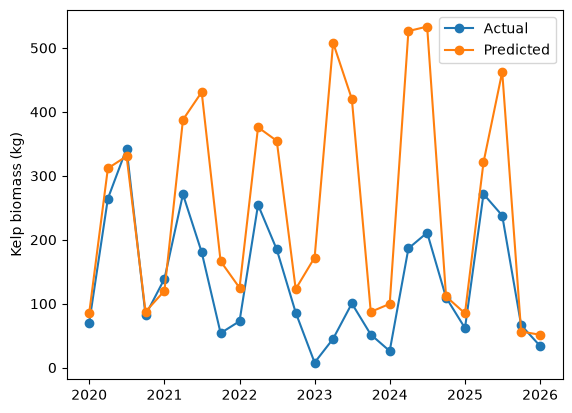

In [28]:
plt.plot(test.quarter, test.kelp_biomass, label="Actual", marker="o")
plt.plot(test.quarter, pred_kg, label="Predicted", marker="o")
plt.legend(); plt.ylabel("Kelp biomass (kg)"); plt.show()

## Random forrest 

In [32]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [35]:
rf_model.fit(
    x_train,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [36]:
rf_pred = rf_model.predict(x_test)

In [37]:
print("Random Forest R2:", r2_score(y_test, rf_pred))

rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
print("Random Forest RMSE:", rmse)

Random Forest R2: -5.461019635330236
Random Forest RMSE: 238.41559882638416


----


# Looking at the light model 

## Linear model

In [14]:
x2 = light_model[
    ["avg_sst",
     "avg_pdo", 
     "avg_cuti",
     "avg_kdpar"]
]
y2 = light_model["kelp_biomass"]

In [15]:
light_model["q"] = light_model.quarter.dt.quarter
train2 = light_model[light_model.quarter < "2020-01-01"]
test2  = light_model[light_model.quarter >= "2020-01-01"]

cols = ["avg_sst", "avg_pdo", "avg_cuti", "avg_kdpar"]
x2_train, y2_train = train2[cols], train2["kelp_biomass"]
x2_test,  y2_test  = test2[cols],  test2["kelp_biomass"]

In [16]:
light_m = smf.ols(
    "np.log(kelp_biomass) ~ avg_sst + avg_pdo + avg_cuti + C(q) + avg_kdpar",
    data=train2
).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

In [17]:
print(light_m.summary())

                             OLS Regression Results                             
Dep. Variable:     np.log(kelp_biomass)   R-squared:                       0.690
Model:                              OLS   Adj. R-squared:                  0.599
Method:                   Least Squares   F-statistic:                     27.26
Date:                  Wed, 04 Nov 2026   Prob (F-statistic):           6.06e-10
Time:                          17:03:22   Log-Likelihood:                -29.452
No. Observations:                    32   AIC:                             74.90
Df Residuals:                        24   BIC:                             86.63
Df Model:                             7                                         
Covariance Type:                    HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     17.6769      3.703

In [48]:
pred_kg2 = np.exp(light_m.predict(test2))
rmse2 = np.sqrt(mean_squared_error(test2.kelp_biomass, pred_kg2))
r2_2 = r2_score(test2.kelp_biomass, pred_kg2)
print("RMSE:" ,rmse2)
print("R2:", r2_2)

RMSE: 129.10393576998464
R2: -0.8945701557905918


In [30]:
compare2 = pd.DataFrame({
    "quarter": test2.quarter,
    "observed": test2.kelp_biomass,
    "predicted": pred_kg2
})

print(compare2)

      quarter    observed   predicted
32 2020-01-01   69.960520   63.158980
33 2020-04-01  264.404434  171.557755
34 2020-07-01  342.731290  205.710496
35 2020-10-01   82.082960   40.324738
36 2021-01-01  138.857267   73.149481
37 2021-04-01  271.134726  294.121163
38 2021-07-01  180.554073  340.476059
39 2021-10-01   53.978529   75.569768
40 2022-01-01   72.580937   69.767301
41 2022-04-01  254.661505  158.224429
42 2022-07-01  184.800097  170.180062
43 2022-10-01   86.167638   67.823503
44 2023-01-01    7.899184  157.498912
45 2023-04-01   45.179641  454.783742
46 2023-07-01  100.385860  293.679659
47 2023-10-01   51.778461   54.528322
48 2024-01-01   25.986289   70.436882
49 2024-04-01  186.431066  443.543425
50 2024-07-01  211.108196  415.312375
51 2024-10-01  109.691788  101.877200
52 2025-01-01   61.866007  110.331330
53 2025-04-01  271.534719  203.957061
54 2025-07-01  237.894648  272.538760
55 2025-10-01   66.457176   31.132421
56 2026-01-01   33.916761   28.199976


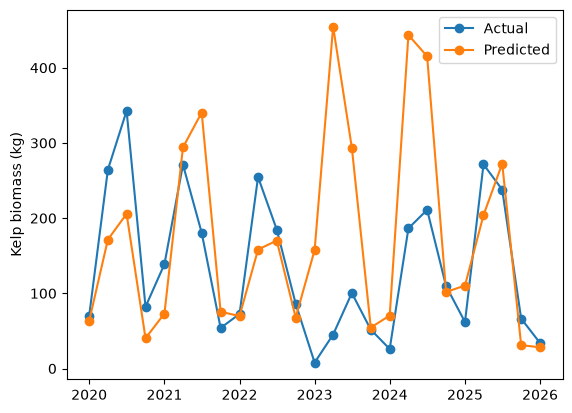

In [31]:
plt.plot(test2.quarter, test2.kelp_biomass, label="Actual", marker="o")
plt.plot(test2.quarter, pred_kg2, label="Predicted", marker="o")
plt.legend(); plt.ylabel("Kelp biomass (kg)"); plt.show()

## Random Forrest

In [44]:

random_2 =rrandom_2 = RandomForestRegressor(n_estimators=100, random_state=42).fit(x2_train, y2_train)

In [45]:
rf_pred2 = random_2.predict(x2_test)

In [47]:
print("Random Forest R2:", r2_score(y2_test, rf_pred2))
rmse3 = np.sqrt(mean_squared_error(y2_test, rf_pred2))
print("Random Forest RMSE:", rmse3)

Random Forest R2: -2.39662781249346
Random Forest RMSE: 172.8654164846363
